In [1]:
import pandas as pd

data=pd.read_csv("ai4i2020.csv")

x = data[["Type","Air temperature [K]","Process temperature [K]","Rotational speed [rpm]","Torque [Nm]","Tool wear [min]"]]
y = data["Machine failure"]

In [2]:
x.head()

,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
0,M,298.1,308.6,1551,42.8,0
1,L,298.2,308.7,1408,46.3,3
2,L,298.1,308.5,1498,49.4,5
3,L,298.2,308.6,1433,39.5,7
4,L,298.2,308.7,1408,40.0,9


In [3]:
x.dtypes

Type                        object
Air temperature [K]        float64
Process temperature [K]    float64
Rotational speed [rpm]       int64
Torque [Nm]                float64
Tool wear [min]              int64
dtype: object

After examining the data types of the features, we found that the `Type` feature is stored as an object data type and contains categorical values. To prepare the dataset for machine learning, we will apply an appropriate encoding technique to convert these categorical values into a numerical representation.

In [4]:
y.value_counts()

Machine failure
0    9661
1     339
Name: count, dtype: int64

The target variable is imbalanced, as the number of healthy machines is much higher than the number of failed machines. Therefore, accuracy alone may be misleading. Precision, recall, and F1-score should also be evaluated

In [5]:
x.isna().sum()

Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
dtype: int64

In [6]:
y.isna().sum()

np.int64(0)

In [7]:
from sklearn.model_selection import train_test_split

x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42,stratify=y)

x_train.shape,x_test.shape

((8000, 6), (2000, 6))

In [8]:
from sklearn.preprocessing import OrdinalEncoder,StandardScaler,OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.metrics import accuracy_score,precision_score,recall_score,precision_recall_curve,confusion_matrix,ConfusionMatrixDisplay
from sklearn.model_selection import cross_val_score

num_feature=["Air temperature [K]","Process temperature [K]","Rotational speed [rpm]","Torque [Nm]","Tool wear [min]"]
cat_faeture=["Type"]

num_pipe=Pipeline([
    ("scale",StandardScaler())
])

cat_pipe=Pipeline([
    ("encoded",OrdinalEncoder())
])

preprocessor=ColumnTransformer([
    ("numeric",num_pipe,num_feature),
    ("categorical",cat_pipe,cat_faeture)
])

logestic

In [9]:
from sklearn.linear_model import LogisticRegression
import matplotlib.pyplot as plt

log_pipe=Pipeline([
    ("process",preprocessor),
    ("model",LogisticRegression(random_state=42))
])

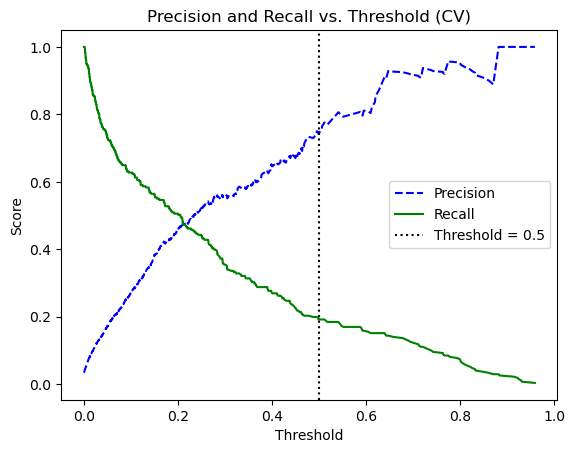

In [10]:
from sklearn.model_selection import cross_val_predict
y_proba_cv = cross_val_predict(
    log_pipe,
    x_train,
    y_train.squeeze(),
    cv=5,
    method="predict_proba"
)[:, 1]

precisions, recalls, pr_thresholds = precision_recall_curve(
    y_train.squeeze(),
    y_proba_cv
)

plt.plot(pr_thresholds, precisions[:-1], "b--", label="Precision")
plt.plot(pr_thresholds, recalls[:-1], "g-", label="Recall")
plt.axvline(0.5, color="black", linestyle=":", label="Threshold = 0.5")
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.legend()
plt.title("Precision and Recall vs. Threshold (CV)")
plt.show()

random forest

In [11]:
from sklearn.ensemble import RandomForestClassifier

forest=Pipeline([
    ("pre",preprocessor),
    ("model",RandomForestClassifier(random_state=42,n_estimators=200))
])

print(cross_val_score(forest,x_train,y_train,cv=5,scoring="recall").mean())

0.5940740740740741


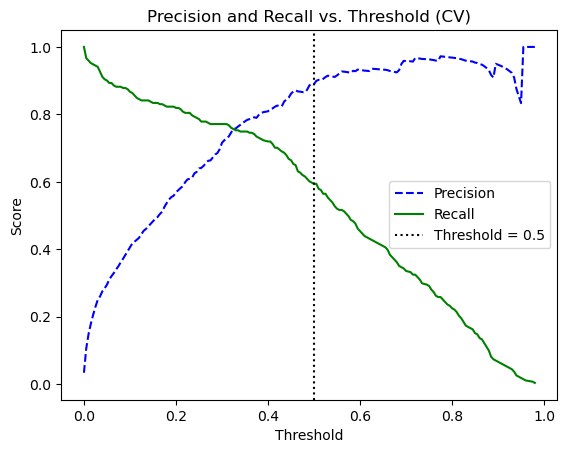

In [12]:
y_proba_cv = cross_val_predict(
    forest,
    x_train,
    y_train.squeeze(),
    cv=5,
    method="predict_proba"
)[:, 1]

precisions, recalls, pr_thresholds = precision_recall_curve(
    y_train.squeeze(),
    y_proba_cv
)

plt.plot(pr_thresholds, precisions[:-1], "b--", label="Precision")
plt.plot(pr_thresholds, recalls[:-1], "g-", label="Recall")
plt.axvline(0.5, color="black", linestyle=":", label="Threshold = 0.5")
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.legend()
plt.title("Precision and Recall vs. Threshold (CV)")
plt.show()

svm

In [13]:
from sklearn.svm import SVC

svm_pipe=Pipeline([
    ("pre",preprocessor),
    ("model",SVC(kernel="rbf"))
])
cross_val_score(svm_pipe,x_train,y_train,cv=5,scoring="recall").mean()

np.float64(0.229023569023569)

naive bayes

In [14]:
from sklearn.naive_bayes import GaussianNB

bayes_pipe=Pipeline([
    ("pre",preprocessor),
    ("model",GaussianNB())
])
cross_val_score(bayes_pipe,x_train,y_train,cv=5,scoring="recall").mean()

np.float64(0.21784511784511787)